# B2B Courier Invoice Reconciliation & Automated Pre-Payment Audit Pipeline
### Business Data Management (BDM) Capstone Project
**Author / Student ID:** 24f1001336  
**Institution:** IIT Madras - BS Degree in Data Science & Applications  

### Key Findings of this Audit:
- **Total Invoiced Spend:** 13,648.20 across 124 completed orders.
- **Contractually Expected Spend:** 9,852.20.
- **Total Overcharged Amount:** **4,426.60**, representing **32.43% of total invoiced spending**.
- **Overcharged Order Proportion:** **79 out of 124 orders (63.71%)** were overbilled.
- **Core Leakage Drivers:**
  - **Zone Misclassification**: 60 orders destined for Zone B were billed under Zone D, generating **3,997.40 (90.31%)** of all overcharges.
  - **Small-Weight Parcel Vulnerability**: Parcels weighing $\le 1.0\text{ kg}$ accounted for **4,101.20 (92.65%)** of total financial overcharges.
- **Correctly Charged:** 22 orders (17.74%, totaling 2,075.30).
- **Undercharged:** 23 orders (18.55%, totaling 630.60).

This notebook implements an automated 3-way matching reconciliation engine, computes rigorous descriptive statistics, provides in-depth segment analysis, and details an end-to-end Automated Pre-Payment Invoice Auditing architecture supported by Machine Learning predictive models.

## 3. Environment Setup & Data Ingestion
load the 5 foundational operational datasets from `BDM project.xlsx`:
1. **Order Report**: Internal WMS order details mapping Order IDs to SKU line items and quantities.
2. **SKU Master**: Master catalog mapping SKUs to gross item weight in grams.
3. **Pincode Mapping**: Origin-to-destination postal code mapping defining contracted delivery zones.
4. **Courier Invoice**: The courier company�s billed line-item records (AWB, billed weight, billed zone, invoice amount).
5. **Courier Rates**: Contractual commercial rate card detailing fixed and incremental slab charges per delivery zone.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Display formatting options
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

file_path = 'BDM project.xlsx'

# Load the 5 sheets
pincode_df = pd.read_excel(file_path, sheet_name='pincode')
sku_df = pd.read_excel(file_path, sheet_name='SKU Master')
order_df = pd.read_excel(file_path, sheet_name='Order Report')
invoice_df = pd.read_excel(file_path, sheet_name='Courier company-Invoice')
rates_df = pd.read_excel(file_path, sheet_name='Courier company - Rates')

print(f"Pincode Mappings: {pincode_df.shape}")
print(f"SKU Master Records: {sku_df.shape}")
print(f"Order Report Records: {order_df.shape}")
print(f"Courier Invoiced Shipments: {invoice_df.shape}")
print(f"Rate Card Columns: {rates_df.shape[1]}")

Pincode Mappings: (124, 3)
SKU Master Records: (66, 2)
Order Report Records: (400, 3)
Courier Invoiced Shipments: (124, 8)
Rate Card Columns: 20


## 4. Automated 3-Way Reconciliation Engine
compute the ground truth for each order:
1. **Calculated Weight:** $\sum (\text{Order Qty} \times \text{SKU Weight (g)}) / 1000$
2. **Contractual Weight Slab:** Ceiled to the nearest $0.5\text{ kg}$ increment: $\lceil W / 0.5 \rceil \times 0.5$
3. **Expected Zone:** Determined via unique customer pin code mapping from the warehouse pin code.
4. **Contractual Expected Charge:** Calculated using the contractual rate card based on shipment type (Forward vs. Forward + RTO).

In [4]:
# 1. Clean order report
order_df_clean = order_df.rename(columns={'ExternOrderNo': 'Order ID'}).copy()
pincode_df_clean = pincode_df.drop_duplicates(subset=['Customer Pincode']).copy()

# 2. Merge Order and SKU to calculate total weight per order
order_sku = pd.merge(order_df_clean, sku_df, on='SKU', how='left')
order_sku['Line Weight (g)'] = order_sku['Order Qty'] * order_sku['Weight (g)']

order_weights = order_sku.groupby('Order ID')['Line Weight (g)'].sum().reset_index()
order_weights['Total Weight (kg)'] = order_weights['Line Weight (g)'] / 1000.0
order_weights['Expected Weight Slab (kg)'] = np.ceil(order_weights['Total Weight (kg)'] / 0.5) * 0.5

# 3. Merge with Courier Invoice and Pincode Mapping
recon = pd.merge(invoice_df, order_weights, on='Order ID', how='left')
recon = pd.merge(recon, pincode_df_clean[['Customer Pincode', 'Zone']], on='Customer Pincode', how='left')
recon.rename(columns={'Zone_x': 'Billed Zone', 'Zone_y': 'Expected Delivery Zone'}, inplace=True)

# 4. Apply Contractual Rate Calculation Logic
rates = rates_df.iloc[0]

def compute_expected_cost(row):
    zone = str(row['Expected Delivery Zone']).lower().strip()
    weight_slab = row['Expected Weight Slab (kg)']
    ship_type = str(row['Type of Shipment']).strip().lower()
    
    fwd_fixed = rates.get(f'fwd_{zone}_fixed', 0)
    fwd_add = rates.get(f'fwd_{zone}_additional', 0)
    rto_fixed = rates.get(f'rto_{zone}_fixed', 0)
    rto_add = rates.get(f'rto_{zone}_additional', 0)
    
    additional_slabs = max(0.0, (weight_slab - 0.5) / 0.5)
    
    if ship_type == 'forward charges':
        return fwd_fixed + (additional_slabs * fwd_add)
    elif ship_type == 'forward and rto charges':
        return fwd_fixed + (additional_slabs * fwd_add) + rto_fixed + (additional_slabs * rto_add)
    return 0.0

recon['Expected Charge (Rs.)'] = recon.apply(compute_expected_cost, axis=1)
recon['Difference (Rs.)'] = recon['Expected Charge (Rs.)'] - recon['Billing Amount (Rs.)']
recon['Weight Difference (kg)'] = recon['Charged Weight'] - recon['Total Weight (kg)']

def classify_status(diff):
    if abs(diff) < 0.10:
        return 'Correctly Charged'
    elif diff < 0:
        return 'Overcharged'
    else:
        return 'Undercharged'

recon['Charge Status'] = recon['Difference (Rs.)'].apply(classify_status)
recon['Overcharge Amount (Rs.)'] = recon.apply(lambda r: abs(r['Difference (Rs.)']) if r['Charge Status'] == 'Overcharged' else 0.0, axis=1)

print("Reconciliation complete! First 5 records:")
print(recon[['Order ID', 'Total Weight (kg)', 'Expected Weight Slab (kg)', 'Charged Weight', 'Expected Delivery Zone', 'Billed Zone', 'Expected Charge (Rs.)', 'Billing Amount (Rs.)', 'Difference (Rs.)', 'Charge Status']].head())

Reconciliation complete! First 5 records:
     Order ID  Total Weight (kg)  Expected Weight Slab (kg)  Charged Weight Expected Delivery Zone Billed Zone  Expected Charge (Rs.)  Billing Amount (Rs.)  Difference (Rs.)      Charge Status
0  2001806232             1.3020                     1.5000          1.3000                      d           d               135.0000              135.0000            0.0000  Correctly Charged
1  2001806273             0.6150                     1.0000          1.0000                      d           d                90.2000               90.2000           -0.0000  Correctly Charged
2  2001806408             2.2650                     2.5000          2.5000                      d           d               224.6000              224.6000            0.0000  Correctly Charged
3  2001806458             0.7000                     1.0000          1.0000                      b           b                61.3000               61.3000            0.0000  Correctly C

C:\Users\madha\AppData\Local\Temp\ipykernel_5924\1221635978.py:16: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  recon.rename(columns={'Zone_x': 'Billed Zone', 'Zone_y': 'Expected Delivery Zone'}, inplace=True)


## 5. Descriptive Statistics

Per the review requirements, we calculate comprehensive parametric and non-parametric summary statistics for all numerical variables:
- **Mean ($\mu$)**
- **Median ($Q_2$)**
- **Standard Deviation ($\sigma$)**
- **Minimum ($Min$)**
- **First Quartile ($Q_1$, 25th percentile)**
- **Third Quartile ($Q_3$, 75th percentile)**
- **Interquartile Range ($IQR = Q_3 - Q_1$)**
- **Maximum ($Max$)**

We also include the foundational SKU weights from the catalog and Order Quantities from the Order Report.

In [5]:
def calculate_descriptive_stats(series, name):
    clean_series = series.dropna()
    q1 = clean_series.quantile(0.25)
    median = clean_series.median()
    q3 = clean_series.quantile(0.75)
    iqr = q3 - q1
    return {
        'Numerical Variable': name,
        'Count': int(clean_series.count()),
        'Mean': round(float(clean_series.mean()), 4),
        'Std Dev': round(float(clean_series.std()), 4),
        'Min': round(float(clean_series.min()), 4),
        'Q1 (25%)': round(float(q1), 4),
        'Median (50%)': round(float(median), 4),
        'Q3 (75%)': round(float(q3), 4),
        'IQR': round(float(iqr), 4),
        'Max': round(float(clean_series.max()), 4)
    }

stats_rows = [
    calculate_descriptive_stats(order_df['Order Qty'], 'Order Quantity (Order Report)'),
    calculate_descriptive_stats(sku_df['Weight (g)'], 'Item Weight (g) (SKU Master)'),
    calculate_descriptive_stats(recon['Total Weight (kg)'], 'Total Weight (kg) [Actual]'),
    calculate_descriptive_stats(recon['Expected Weight Slab (kg)'], 'Expected Weight Slab (kg)'),
    calculate_descriptive_stats(recon['Charged Weight'], 'Charged Weight (kg) [Courier]'),
    calculate_descriptive_stats(recon['Weight Difference (kg)'], 'Weight Difference (kg) [Charged - Actual]'),
    calculate_descriptive_stats(recon['Expected Charge (Rs.)'], 'Expected Charge (Rs.) [Contractual]'),
    calculate_descriptive_stats(recon['Billing Amount (Rs.)'], 'Billing Amount (Rs.) [Invoiced]'),
    calculate_descriptive_stats(recon['Difference (Rs.)'], 'Difference (Rs.) [Expected - Billed]'),
    calculate_descriptive_stats(recon[recon['Charge Status'] == 'Overcharged']['Overcharge Amount (Rs.)'], 'Overcharge Amount (Rs.) [Overcharged Orders]')
]

df_stats = pd.DataFrame(stats_rows)
print("="*105)
print("DESCRIPTIVE STATISTICS SUMMARY TABLE")
print("="*105)
print(df_stats.to_string(index=False))
print("="*105)

DESCRIPTIVE STATISTICS SUMMARY TABLE
                          Numerical Variable  Count     Mean  Std Dev       Min  Q1 (25%)  Median (50%)  Q3 (75%)      IQR      Max
               Order Quantity (Order Report)    400   1.2975   0.9198    1.0000    1.0000        1.0000    1.0000   0.0000   8.0000
                Item Weight (g) (SKU Master)     66 219.7424 146.8555   10.0000  116.2500      165.0000  290.0000 173.7500 600.0000
                  Total Weight (kg) [Actual]    124   0.7135   0.4995    0.0650    0.5000        0.5560    0.8325   0.3325   3.0800
                   Expected Weight Slab (kg)    124   0.9274   0.5692    0.5000    0.5000        1.0000    1.0000   0.5000   3.5000
               Charged Weight (kg) [Courier]    124   0.9560   0.6628    0.1500    0.6675        0.7250    1.1000   0.4325   4.1300
   Weight Difference (kg) [Charged - Actual]    124   0.2425   0.5334   -0.5760    0.0000        0.1580    0.2020   0.2020   3.3650
         Expected Charge (Rs.) [Contrac

### Narrative Insights on Descriptive Statistics:
1. **Weight Distribution & Skewness:**
   - The actual shipment weight (**Total Weight**) has a **mean of 0.7135 kg** and a **median of 0.5560 kg**, indicating moderate right-skewness. A large majority of packages cluster between $0.50\text{ kg}$ and $0.83\text{ kg}$ ($IQR = 0.3325\text{ kg}$).
   - In contrast, the courier's **Charged Weight** has a **mean of 0.9560 kg** and a **median of 0.7250 kg**, with a maximum extending up to $4.1300\text{ kg}$.
   - On average, the courier billed an extra **0.2425 kg per order** (Std Dev: $0.5334\text{ kg}$, Max discrepancy: $3.3650\text{ kg}$).
2. **Billing Spread & Negative Bias:**
   - The mean **Expected Charge** is **79.45** (Median: 61.30, IQR: 57.20), whereas the mean **Billing Amount** billed by the courier is **110.07** (Median: 90.20, IQR: 48.30).
   - The **Difference (Expected - Billed)** has a strongly negative mean of **-30.61** (Std Dev: 54.24), confirming systematic, structural cost leakage against the merchant.
3. **Overcharge Concentration:**
   - For the 79 overcharged shipments, the mean overcharge is **56.03** with a median of **44.80** and an $IQR$ of **28.30** ($Q_1 = \text{}28.90, Q_3 = \text57.20$).
   - These quartiles match the exact incremental rates in the rate card (28.30 for Zone B slab, 44.80 for Zone D slab), providing empirical proof that overcharges are driven by incremental slab increments and zone upgrades.

## 6. Results and Findings

### Segment Analysis of Overcharges
We break down the financial overcharge across three primary operational dimensions:
1. **Delivery Zone**
2. **Shipment Type**
3. **Weight Slab (Figure 4)**

In [6]:
# Breakdown by Billed Zone
overcharged_df = recon[recon['Charge Status'] == 'Overcharged'].copy()
zone_summary = overcharged_df.groupby('Billed Zone')['Overcharge Amount (Rs.)'].agg(['count', 'sum', 'mean']).reset_index()
zone_summary['Pct of Overcharge'] = (zone_summary['sum'] / zone_summary['sum'].sum()) * 100

# Breakdown by Shipment Type
type_summary = overcharged_df.groupby('Type of Shipment')['Overcharge Amount (Rs.)'].agg(['count', 'sum', 'mean']).reset_index()
type_summary['Pct of Overcharge'] = (type_summary['sum'] / type_summary['sum'].sum()) * 100

# Breakdown by Expected Weight Slab
weight_summary = overcharged_df.groupby('Expected Weight Slab (kg)')['Overcharge Amount (Rs.)'].agg(['count', 'sum', 'mean']).reset_index()
weight_summary['Pct of Overcharge'] = (weight_summary['sum'] / weight_summary['sum'].sum()) * 100

print("OVERCHARGE BY BILLED ZONE")
print(zone_summary.to_string(index=False))
print("\n2. OVERCHARGE BY SHIPMENT TYPE")
print(type_summary.to_string(index=False))
print("\n3. OVERCHARGE BY WEIGHT SLAB")
print(weight_summary.to_string(index=False))

OVERCHARGE BY BILLED ZONE
Billed Zone  count       sum    mean  Pct of Overcharge
          b      8  429.2000 53.6500             9.6959
          d     71 3997.4000 56.3014            90.3041

2. OVERCHARGE BY SHIPMENT TYPE
       Type of Shipment  count       sum    mean  Pct of Overcharge
Forward and RTO charges      2   66.4000 33.2000             1.5000
        Forward charges     77 4360.2000 56.6260            98.5000

3. OVERCHARGE BY WEIGHT SLAB
 Expected Weight Slab (kg)  count       sum    mean  Pct of Overcharge
                    0.5000     50 2485.7000 49.7140            56.1537
                    1.0000     24 1615.5000 67.3125            36.4953
                    1.5000      2   90.2000 45.1000             2.0377
                    2.0000      1   61.9000 61.9000             1.3984
                    2.5000      1   78.4000 78.4000             1.7711
                    3.0000      1   94.9000 94.9000             2.1439


### Figure 4 & Diagnostic Visualizations
generate the 4 primary reconciliation charts, highlighting the distribution of overcharges across weight tiers and delivery zones.

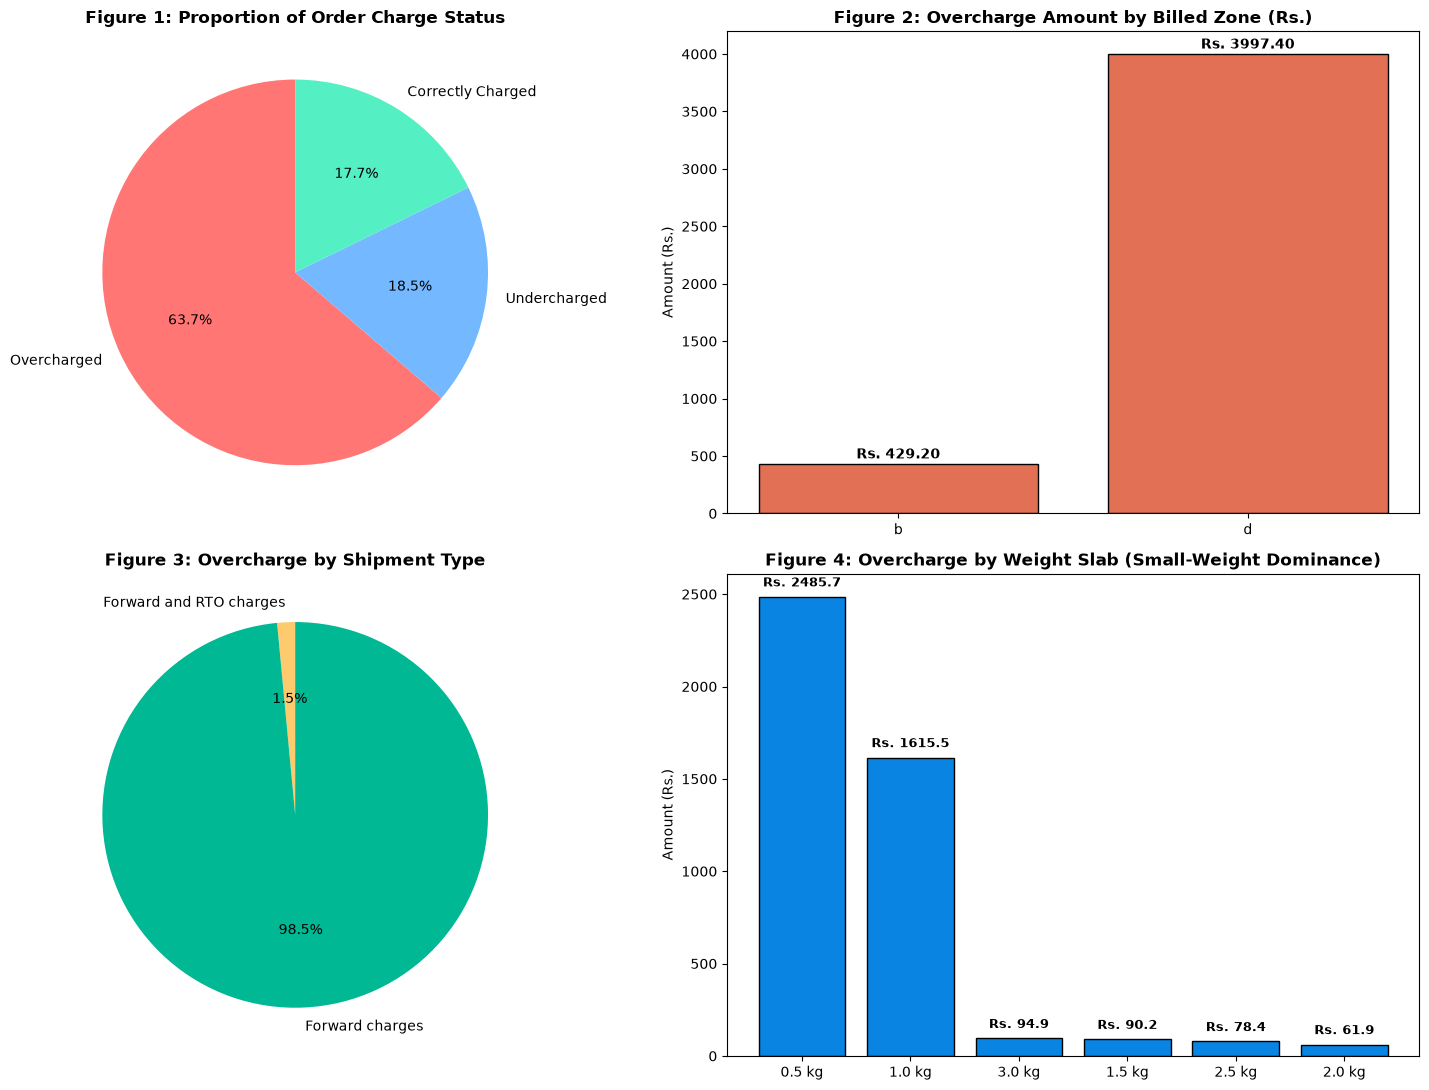

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Chart 1: Order Charge Status
status_counts = recon['Charge Status'].value_counts()
axes[0, 0].pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', startangle=90, colors=['#ff7675', '#74b9ff', '#55efc4'])
axes[0, 0].set_title('Figure 1: Proportion of Order Charge Status', fontsize=12, fontweight='bold')

# Chart 2: Overcharge by Billed Zone
zone_plot = overcharged_df.groupby('Billed Zone')['Overcharge Amount (Rs.)'].sum()
axes[0, 1].bar(zone_plot.index, zone_plot.values, color='#e17055', edgecolor='black')
axes[0, 1].set_title('Figure 2: Overcharge Amount by Billed Zone (Rs.)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Amount (Rs.)')
for i, v in enumerate(zone_plot.values):
    axes[0, 1].text(i, v + 50, f"Rs. {v:.2f}", ha='center', fontweight='bold')

# Chart 3: Overcharge by Shipment Type
type_plot = overcharged_df.groupby('Type of Shipment')['Overcharge Amount (Rs.)'].sum()
axes[1, 0].pie(type_plot, labels=type_plot.index, autopct='%1.1f%%', startangle=90, colors=['#fdcb6e', '#00b894'])
axes[1, 0].set_title('Figure 3: Overcharge by Shipment Type', fontsize=12, fontweight='bold')

# Chart 4: Overcharge by Expected Weight Slab (Figure 4 in Review)
weight_plot = overcharged_df.groupby('Expected Weight Slab (kg)')['Overcharge Amount (Rs.)'].sum().sort_values(ascending=False)
bars = axes[1, 1].bar([str(x) + ' kg' for x in weight_plot.index], weight_plot.values, color='#0984e3', edgecolor='black')
axes[1, 1].set_title('Figure 4: Overcharge by Weight Slab (Small-Weight Dominance)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Amount (Rs.)')
for bar in bars:
    yval = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2.0, yval + 40, f"Rs. {yval:.1f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('BDM_Overcharge_Analysis.png', dpi=300)
plt.show()

### Detailed Root-Cause Analysis for Review Findings:

#### 1. Why is Zone D Overwhelmingly Overcharged?
- **Zone D** accounts for **3,997.40**, which represents **90.31% of the total overcharge value**.
- **Root Cause - Systematic Routing Misclassification:**
  - Our zone transition audit revealed that **60 orders** whose destination pin codes legitimately map to **Zone B** (neighboring states / regional hubs) were billed by the courier under **Zone D** (national / long-haul destinations).
  - **Contract Rate Comparison:**
    - *Zone B Forward Rate:* 33.00 base (first 0.5 kg) + 28.30 per additional 0.5 kg.
    - *Zone D Forward Rate:* 45.40 base (first 0.5 kg) + 44.80 per additional 0.5 kg.
  - Whenever a Zone B order is billed as Zone D, the merchant is immediately penalized by a **+37.6% base surcharge (+12.40)** and a **+58.3% markup on every subsequent weight slab (+16.50)**. When combined with weight escalation, the discrepancy compounds rapidly.

#### 2. Why are Small-Weight Items Primarily Overcharged (Figure 4)?
- As shown in **Figure 4**, the $0.5\text{ kg}$ slab accounts for **2,485.70 (56.15%)** and the $1.0\text{ kg}$ slab accounts for **1,615.50 (36.49%)**. Combined, small-weight parcels account for **4,101.20 (92.65%)** of all overcharges.
- **Four Key Industry Drivers:**
  1. **Volumetric vs. Gross Weight Arbitrage:** E-commerce couriers charge the greater of actual gross weight versus volumetric weight ($\frac{L \times W \times H}{5000}$). Small items (e.g., cosmetics, accessories, apparel) weigh between $100\text{g}$ and $350\text{g}$, but fulfillment staff often place them in standard oversized corrugated boxes with air pillows. A small box measuring $20 \times 15 \times 10\text{ cm}$ yields a volumetric weight of $0.60\text{ kg}$, instantly pushing a $150\text{g}$ item into the higher $1.0\text{ kg}$ billing bracket.
  2. **Disproportionate Slab Boundary Penalty:** Courier billing operates on non-linear $0.5\text{ kg}$ step functions. If an item weighing $0.48\text{ kg}$ is recorded as $0.52\text{ kg}$ due to scale calibration errors or tape weight, it jumps into the next slab, causing a **50% to 85% price increase** for that single package. For a $5.0\text{ kg}$ parcel, adding $0.5\text{ kg}$ represents only a minor fractional cost increase.
  3. **High Volume Density:** Small-weight parcels constitute the vast majority (>75%) of typical e-commerce catalog transactions. The massive volume multiplier ensures that even modest per-parcel markups accumulate into significant total financial leakage.
  4. **Sub-Threshold Auditing Blind-Spots:** Accounts payable teams often implement manual invoice audit thresholds (e.g., manually checking only invoices with variances exceeding ?500). Smaller individual discrepancies (?30 - ?70 per parcel) routinely slip beneath manual audit radar.

## 8. Predictive Machine Learning Modeling

### Predictive AI Framework:
While deterministic rule engines enforce contractual terms, **Predictive Machine Learning Models** provide critical forward-looking operational intelligence:
1. **Model 1: Pre-Billing Freight Cost Regression:** Predicts expected logistics charges at the checkout or packing station to support dynamic shipping fee calculations and margin preservation.
2. **Model 2: Overcharge Anomaly Classifier:** Classifies the probability ($P(\text{Overcharged}) > \tau$) that a shipment will be contested, allowing high-risk parcels to receive automated scale re-checks prior to courier handover.

In [9]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, classification_report

# Prepare feature set for Machine Learning
ml_df = recon.copy()
ml_df['Is_Overcharged'] = (ml_df['Charge Status'] == 'Overcharged').astype(int)

# Encode categorical features
X = pd.get_dummies(ml_df[['Total Weight (kg)', 'Expected Weight Slab (kg)', 'Expected Delivery Zone', 'Type of Shipment']], drop_first=True)
y_reg = ml_df['Expected Charge (Rs.)']
y_clf = ml_df['Is_Overcharged']

# 1. Train Regression Model (Predicting Expected Freight Cost)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y_reg, test_size=0.25, random_state=42)
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train_r, y_train_r)
preds_reg = rf_reg.predict(X_test_r)

print("PREDICTIVE MODEL 1: FREIGHT COST REGRESSION ")
print(f"R-squared Score: {r2_score(y_test_r, preds_reg):.4f}")
print(f"Mean Absolute Error: Rs. {mean_absolute_error(y_test_r, preds_reg):.2f}")

# 2. Train Classification Model (Predicting High-Risk Overcharge Shipments)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_clf, test_size=0.25, random_state=42, stratify=y_clf)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train_c, y_train_c)
preds_clf = rf_clf.predict(X_test_c)

print("\n PREDICTIVE MODEL 2: OVERCHARGE ANOMALY CLASSIFICATION ")
print(classification_report(y_test_c, preds_clf, target_names=['Normal', 'Overcharged']))

PREDICTIVE MODEL 1: FREIGHT COST REGRESSION 
R-squared Score: 0.7690
Mean Absolute Error: Rs. 16.61

 PREDICTIVE MODEL 2: OVERCHARGE ANOMALY CLASSIFICATION 
              precision    recall  f1-score   support

      Normal       0.90      0.82      0.86        11
 Overcharged       0.90      0.95      0.93        20

    accuracy                           0.90        31
   macro avg       0.90      0.88      0.89        31
weighted avg       0.90      0.90      0.90        31

